# Respuesta del monocromador al 852 y al 822

Cada archivo `data/MC-<λ>.txt` es una toma con el monocromador fijo en la longitud de onda $\lambda_\mathrm{mono}$ del nombre, en pasos de 0.2 nm (`MC-852.txt` es 852.0 nm). La luz llega al SPCM a través del monocromador y se registran los conteos por lectura. Hay dos series:

* **Viendo al 852** (`MC-850` … `MC-854.4`): solo el láser de 852 nm contribuye a los conteos.
* **Viendo al 822** (`MC-820` … `MC-823`): solo el láser de 822 nm contribuye a los conteos.

Potencias (`data/readme.txt`): 822 nm, 0.66 mW; 852 nm, 0.104 mW.

Columnas de cada archivo: `[?, λ del láser (nm, medidor de onda), canal A, canal B (conteos SPCM), ν del láser (THz)]`. El canal A está en 0 en todas las tomas, así que la señal es el canal B.

In [1]:
import os, glob, re
import numpy as np
import matplotlib.pyplot as plt

BASE = '.'

C1, C2, C3, INK, GRID = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#8a8984'
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.3, 'axes.spines.top': False, 'axes.spines.right': False})

with open(os.path.join(BASE, 'data', 'readme.txt'), encoding='utf-8') as fh:
    POT = {int(l): float(p) for l, p in re.findall(r'(\d{3})\D*?([\d.]+)\s*mW', fh.read())}  # mW
print('Potencias (mW):', POT)

Potencias (mW): {822: 0.66, 852: 0.104}


## Lectura

Se descartan las lecturas con 0 cuentas (las primeras una o dos de cada archivo, antes de que el contador entregue datos). Para cada toma se guarda el promedio de los conteos, su desviación estándar $\sigma$ (fluctuación entre lecturas) y el error del promedio $\sigma/\sqrt{N}$. El láser que contribuye se identifica por la λ del medidor de onda.

In [2]:
def load(path):
    d = np.loadtxt(path)
    k = d[:, 3] > 0
    B = d[k, 3]
    return dict(lam_mono=float(os.path.basename(path)[3:-4]), laser=int(round(d[k, 1].mean())), lam_laser=d[k, 1].mean(),
                B=B, m=B.mean(), s=B.std(ddof=1), sem=B.std(ddof=1)/np.sqrt(len(B)), n_desc=int((~k).sum()))

files = sorted(glob.glob(os.path.join(BASE, 'data', 'MC-*.txt')))
tomas = sorted((load(f) for f in files), key=lambda t: t['lam_mono'])
SERIE = {L: [t for t in tomas if t['laser'] == L] for L in (852, 822)}

print(f"{'láser':>5s} {'λ mono (nm)':>11s} {'N':>4s} {'desc.':>5s} {'promedio':>9s} {'σ':>7s} {'σ/√N':>6s}")
for L, ts in SERIE.items():
    for t in ts:
        print(f"{L:5d} {t['lam_mono']:11.1f} {len(t['B']):4d} {t['n_desc']:5d} {t['m']:9.1f} {t['s']:7.1f} {t['sem']:6.1f}")
    print(f"      λ láser (medidor de onda) = {np.mean([t['lam_laser'] for t in ts]):.5f} nm\n")

láser λ mono (nm)    N desc.  promedio       σ   σ/√N
  852       850.0  162     1     426.4    66.2    5.2
  852       850.2  114     1     468.0    75.2    7.0
  852       850.4  119     1     458.1    67.0    6.1
  852       850.6   97     1     802.3    79.3    8.1
  852       850.8  124     1     788.3    91.3    8.2
  852       851.0  151     1    2523.3   174.0   14.2
  852       851.2  130     2    2583.9   180.1   15.8
  852       851.4  133     1    2351.0   204.2   17.7
  852       851.6  168     2    7913.5   476.7   36.8
  852       851.8  122     1    7631.1   369.4   33.4
  852       852.0  147     1    5249.0   241.1   19.9
  852       852.2  154     1    5021.0   426.9   34.4
  852       852.4  144     1     551.6    85.4    7.1
  852       852.6  160     1     508.3    80.7    6.4
  852       852.8  121     1     278.1    58.7    5.3
  852       853.0  167     2     266.5    50.1    3.9
  852       853.2  319     1     254.0    54.4    3.0
  852       853.4   97     1

## Conteos promedio en función de $\lambda_\mathrm{mono}$

Los puntos grises son las lecturas individuales de cada toma (con un pequeño desplazamiento horizontal aleatorio para que no se superpongan); los círculos son el promedio, con barras de $\pm\sigma$. La línea vertical punteada marca la λ del láser medida con el medidor de onda.

In [3]:
def plot_serie(L, color):
    ts = SERIE[L]
    lm = np.array([t['lam_mono'] for t in ts])
    m = np.array([t['m'] for t in ts])
    s = np.array([t['s'] for t in ts])
    lam_laser = np.mean([t['lam_laser'] for t in ts])
    rng = np.random.default_rng(0)

    fig, ax = plt.subplots(figsize=(10, 5))
    for t in ts:
        ax.plot(t['lam_mono'] + rng.uniform(-0.03, 0.03, len(t['B'])), t['B'], '.', ms=2, color=GRID, alpha=0.35, zorder=1)
    ax.plot(lm, m, '-', lw=1, color=color, alpha=0.6, zorder=2)
    ax.errorbar(lm, m, yerr=s, fmt='o', ms=6, color=color, ecolor=color, elinewidth=1.2, capsize=3, zorder=3,
                label='promedio ± σ')
    ax.axvline(lam_laser, ls=':', lw=1.2, color=INK)
    ax.annotate(f'λ láser = {lam_laser:.3f} nm', (lam_laser, 1), xycoords=('data', 'axes fraction'),
                xytext=(4, -14), textcoords='offset points', fontsize=9, color=INK)
    ax.set_xticks(lm)
    ax.set_xticklabels([f'{x:.1f}' for x in lm], rotation=45)
    ax.set_xlabel('λ del monocromador (nm)')
    ax.set_ylabel('Conteos B por lectura (SPCM)')
    ax.set_title(f'Viendo al {L}: solo contribuye el láser de {L} nm ({POT[L]:g} mW)')
    ax.set_ylim(bottom=0)
    ax.legend(loc='upper left')
    fig.tight_layout()
    return fig, ax

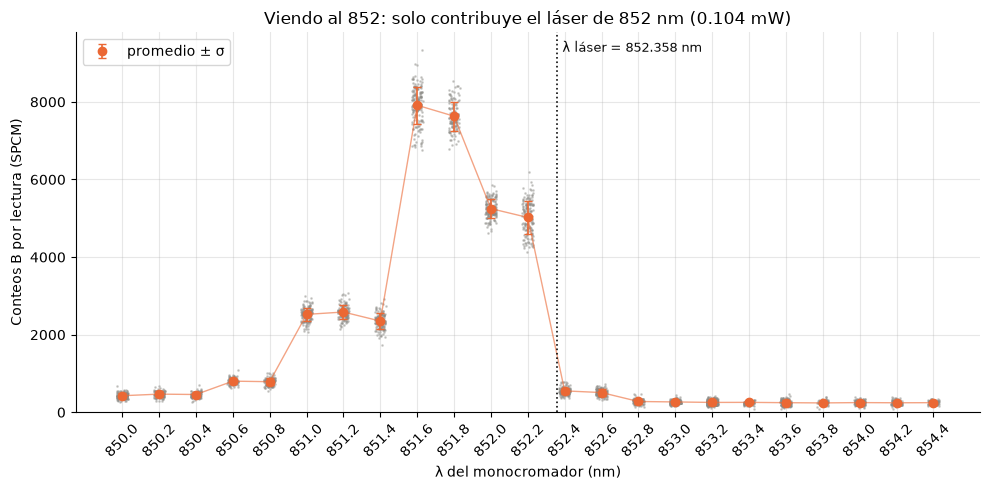

In [4]:
fig852, ax852 = plot_serie(852, C2)
plt.show()

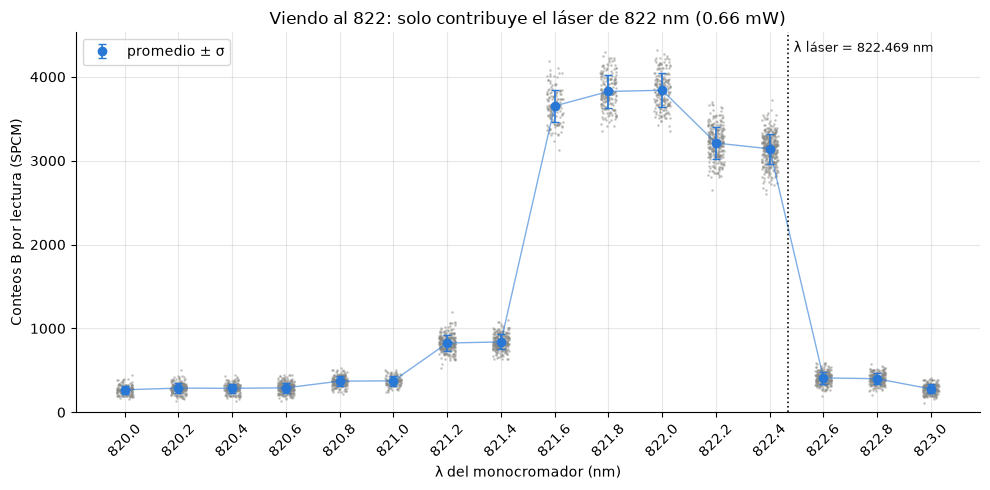

In [5]:
fig822, ax822 = plot_serie(822, C1)
plt.show()